# 实验5 简化 VGG 对 CIFAR10 分类

课程总页称 VGG16，但本飞书指导实际使用 8 个卷积层的简化 VGG。本 Notebook 按指导的简化网络配置，不替换成另一种标准 VGG16。训练使用随机裁剪与水平翻转，测试集不使用随机增强。

[原实验指导](https://oucaigroup.feishu.cn/wiki/UJ1xwmjVziixTckP1zFcgNgcnqc)

在 Colab：上传本 ipynb → 选择 GPU → 从上到下运行。三个 Notebook 各自独立，无需上传其他源码。下方没有预填训练输出，指标与图片由真实运行生成。


## 1 环境检查

Colab 通常已带 PyTorch、Torchvision、NumPy 和 Matplotlib。此处打印实际版本和设备，不强行覆盖 Colab 预装的 GPU 环境。若缺包，先看文件夹中的运行说明；GPU 应在开始运行前选好。


In [1]:
import csv
import json
import math
import platform
import random
import shutil
import sys
import time
from datetime import datetime
from pathlib import Path

try:
    import numpy as np
    import matplotlib.pyplot as plt
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torch.utils.data import DataLoader, Subset
    from torchvision import datasets, transforms
except ImportError as exc:
    raise RuntimeError(
        "缺少依赖。在 Colab 中选择 Python 3 运行环境；本地先安装 requirements.txt。"
    ) from exc

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("当前使用 CPU；完整训练建议在 Colab 选择 GPU。")


Python: 3.12.14
PyTorch: 2.8.0+cu128 Torchvision: 0.23.0+cu128
Device: cuda:0
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2 实验参数

默认参数对应指导。首次只想检查流程，可把 smoke_test 改为 True；正式实验再改回 False，并从本单元重新运行到最后。download_results=True 可在 Colab 最后自动下载结果。


In [2]:
# 所有可调参数集中在这里；正式实验保持 smoke_test=False。
EXPERIMENT_ID = 'lab05_vgg_cifar10'
SOURCE_URL = 'https://oucaigroup.feishu.cn/wiki/UJ1xwmjVziixTckP1zFcgNgcnqc'
CFG = {'seed': 42,
 'data_root': './data',
 'output_root': './outputs',
 'smoke_test': False,
 'save_models': True,
 'download_results': False,
 'dataset': 'CIFAR10',
 'epochs': 10,
 'train_batch_size': 128,
 'test_batch_size': 128,
 'optimizer': 'Adam',
 'learning_rate': 0.001,
 'augmentation': True}
CFG['num_workers'] = 0 if platform.system() == 'Windows' else 2
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2023, 0.1994, 0.201)
CLASSES = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
set_config_note = 'smoke_test=True 时仅取真实数据 1024/256 张、训练 1 轮。'
assert CFG['epochs'] >= 1 and CFG['train_batch_size'] >= 2


## 3 训练 测试与可视化工具

训练与测试分离，测试使用 eval 和 inference_mode；每个 epoch 保存日志。测试集用于观察固定轮次的结果，不按测试准确率挑选最佳模型或调参。


In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    # DataLoader 会设置每个 worker 的 torch 种子；同步 Python 和 numpy。
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed)
    np.random.seed(seed)


def create_run_directory():
    run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    directory = Path(CFG["output_root"]) / EXPERIMENT_ID / run_id
    directory.mkdir(parents=True, exist_ok=False)
    config = {
        "experiment": EXPERIMENT_ID, "source": SOURCE_URL, "config": CFG,
        "device": str(DEVICE), "torch": str(torch.__version__),
        "torchvision": str(torchvision.__version__), "python": sys.version,
        "mean": MEAN, "std": STD, "classes": CLASSES,
        "scope": "real-data subset smoke test" if CFG["smoke_test"] else "full dataset",
    }
    (directory / "config.json").write_text(
        json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("Outputs:", directory.resolve())
    if CFG["smoke_test"]:
        print("SMOKE TEST：真实数据小子集，仅检查流程，不能当作完整实验成绩。")
    return directory


def load_datasets():
    train_steps = []
    if CFG["augmentation"]:
        train_steps += [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
    normalize = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    train_transform = transforms.Compose(train_steps + normalize)
    test_transform = transforms.Compose(normalize)
    dataset_class = datasets.MNIST if CFG["dataset"] == "MNIST" else datasets.CIFAR10
    try:
        train_data = dataset_class(CFG["data_root"], train=True, download=True, transform=train_transform)
        test_data = dataset_class(CFG["data_root"], train=False, download=True, transform=test_transform)
    except Exception as exc:
        raise RuntimeError(
            "真实数据集读取或下载失败。请检查网络、磁盘与 data_root，修复后重跑本单元；"
            "本代码不会自动切换到随机数据。"
        ) from exc
    if CFG["smoke_test"]:
        generator = torch.Generator().manual_seed(CFG["seed"])
        train_indices = torch.randperm(len(train_data), generator=generator)[:1024].tolist()
        test_indices = torch.randperm(len(test_data), generator=generator)[:256].tolist()
        train_data = Subset(train_data, train_indices)
        test_data = Subset(test_data, test_indices)
    print("Training samples:", len(train_data), "Test samples:", len(test_data))
    print("Train transform:", train_transform)
    print("Test transform:", test_transform)
    return train_data, test_data


def make_loader(dataset, training):
    generator = torch.Generator().manual_seed(CFG["seed"])
    return DataLoader(
        dataset,
        batch_size=CFG["train_batch_size"] if training else CFG["test_batch_size"],
        shuffle=training,
        num_workers=CFG["num_workers"],
        pin_memory=DEVICE.type == "cuda",
        worker_init_fn=seed_worker,
        generator=generator,
    )


def display_image(ax, image):
    image = image.detach().cpu()
    mean = torch.tensor(MEAN).view(-1, 1, 1)
    std = torch.tensor(STD).view(-1, 1, 1)
    image = (image * std + mean).clamp(0, 1)
    if image.shape[0] == 1:
        ax.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=1)
    else:
        ax.imshow(image.permute(1, 2, 0).numpy())
    ax.axis("off")


def show_samples(dataset, directory):
    count = min(16, len(dataset))
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for index, ax in enumerate(axes.flat):
        if index < count:
            image, label = dataset[index]
            display_image(ax, image)
            ax.set_title(CLASSES[int(label)])
        else:
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(directory / "data_samples.png", dpi=160)
    plt.show()
    plt.close(fig)


def apply_permutation(images, permutation):
    if permutation is None:
        return images
    if tuple(images.shape[1:]) != (1, 28, 28) or permutation.numel() != 784:
        raise ValueError("像素置换只用于 1×28×28 的 MNIST 图像。")
    return images.flatten(1)[:, permutation].reshape_as(images)


def forward_shape_table(model, input_shape):
    hooks = []
    records = []
    def record(name):
        def hook(module, inputs, output):
            records.append((name, type(module).__name__, tuple(output.shape)))
        return hook
    for name, module in model.named_modules():
        if name and not list(module.children()):
            hooks.append(module.register_forward_hook(record(name)))
    previous_mode = model.training
    try:
        model.eval()
        with torch.inference_mode():
            output = model(torch.zeros(input_shape, device=DEVICE))
        assert tuple(output.shape) == (input_shape[0], 10), tuple(output.shape)
    finally:
        for hook in hooks:
            hook.remove()
        model.train(previous_mode)
    print("Layer | Type | Output shape")
    for row in records:
        print(" | ".join(map(str, row)))
    print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
    return records


def train_one_epoch(model, loader, criterion, optimizer, permutation=None):
    model.train()
    loss_sum, correct, count = 0.0, 0, 0
    for batch_index, (images, labels) in enumerate(loader):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        images = apply_permutation(images, permutation)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise FloatingPointError("训练损失不是有限值，请检查输入与学习率。")
        loss.backward()
        optimizer.step()
        size = labels.size(0)
        loss_sum += loss.item() * size
        correct += (logits.argmax(1) == labels).sum().item()
        count += size
        if batch_index % 100 == 0:
            print(f"  Batch {batch_index + 1}/{len(loader)} | loss={loss.item():.4f}")
    return loss_sum / count, 100.0 * correct / count


@torch.inference_mode()
def evaluate(model, loader, criterion, permutation=None):
    # VGG 含 BatchNorm，测试必须切换 eval，防止更新统计量。
    model.eval()
    loss_sum, correct, count = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(apply_permutation(images, permutation))
        loss_sum += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        count += labels.size(0)
    return loss_sum / count, 100.0 * correct / count, count


def fit_model(model, name, train_data, test_data, directory, criterion, permutation=None):
    # 每个模型重置随机种子与 loader，控制初始化、批次顺序和数据增强。
    set_seed(CFG["seed"])
    train_loader = make_loader(train_data, True)
    test_loader = make_loader(test_data, False)
    optimizer_class = torch.optim.SGD if CFG["optimizer"] == "SGD" else torch.optim.Adam
    optimizer_options = {"lr": CFG["learning_rate"]}
    if CFG["optimizer"] == "SGD":
        optimizer_options["momentum"] = CFG["momentum"]
    optimizer = optimizer_class(model.parameters(), **optimizer_options)
    if permutation is not None:
        permutation = permutation.to(DEVICE)
    history = []
    model_directory = directory / name
    model_directory.mkdir(parents=True, exist_ok=True)
    epochs = 1 if CFG["smoke_test"] else CFG["epochs"]
    print(f"\n{name}: {sum(p.numel() for p in model.parameters()):,} parameters, {epochs} epoch(s)")
    for epoch in range(1, epochs + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, permutation)
        test_loss, test_accuracy, tested = evaluate(model, test_loader, criterion, permutation)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        record = {
            "epoch": epoch, "train_loss": train_loss, "train_accuracy_pct": train_accuracy,
            "test_loss": test_loss, "test_accuracy_pct": test_accuracy,
            "test_samples": tested, "train_plus_test_seconds": time.perf_counter() - started,
        }
        history.append(record)
        print(f"Epoch {epoch}/{epochs} | train loss {train_loss:.4f} | "
              f"test loss {test_loss:.4f} | test accuracy {test_accuracy:.2f}% ({tested} samples)")
        with (model_directory / "history.csv").open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(record))
            writer.writeheader()
            writer.writerows(history)
    if CFG["save_models"]:
        torch.save({
            "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
            "model_name": name, "config": CFG, "classes": CLASSES,
            "permutation": None if permutation is None else permutation.detach().cpu(),
        }, model_directory / "model.pt")
    return {"name": name, "parameters": sum(p.numel() for p in model.parameters()),
            "history": history, "permutation": permutation, "model": model}


@torch.inference_mode()
def show_predictions(result, dataset, directory):
    model = result["model"]
    model.eval()
    count = min(8, len(dataset))
    samples = [dataset[index] for index in range(count)]
    images = torch.stack([sample[0] for sample in samples])
    labels = [int(sample[1]) for sample in samples]
    model_input = apply_permutation(images.to(DEVICE), result["permutation"])
    predicted = model(model_input).argmax(1).cpu().tolist()
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    rows = []
    for index, ax in enumerate(axes.flat):
        if index >= count:
            ax.axis("off")
            continue
        # 像素打乱模型也展示它实际看到的图像。
        display_image(ax, model_input[index])
        ax.set_title(f"True: {CLASSES[labels[index]]}\nPred: {CLASSES[predicted[index]]}",
                     color="green" if labels[index] == predicted[index] else "red")
        rows.append({"index": index, "true": CLASSES[labels[index]], "predicted": CLASSES[predicted[index]]})
    fig.suptitle(result["name"])
    fig.tight_layout()
    fig.savefig(directory / f"{result['name']}_predictions.png", dpi=160)
    plt.show()
    plt.close(fig)
    (directory / f"{result['name']}_predictions.json").write_text(
        json.dumps(rows, ensure_ascii=False, indent=2), encoding="utf-8"
    )


def save_comparison(results, directory):
    summary = []
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for result in results:
        history = result["history"]
        summary.append({"model": result["name"], "parameters": result["parameters"], **history[-1]})
        epochs = [row["epoch"] for row in history]
        axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label=result["name"])
        axes[1].plot(epochs, [row["test_accuracy_pct"] for row in history], marker="o", label=result["name"])
    axes[0].set_title("Training loss")
    axes[1].set_title("Test accuracy (%)")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(directory / "training_curves.png", dpi=160)
    plt.show()
    plt.close(fig)
    with (directory / "summary.csv").open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(summary[0]))
        writer.writeheader()
        writer.writerows(summary)
    print("\nModel | Parameters | Test accuracy (%)")
    for row in summary:
        print(f"{row['model']} | {row['parameters']:,} | {row['test_accuracy_pct']:.2f}")
    return summary


def export_results(directory):
    archive = shutil.make_archive(str(directory), "zip", root_dir=directory)
    print("Results ZIP:", archive)
    print("请同时保存带运行输出的 Notebook，作为报告截图的原始依据。")
    if CFG["download_results"]:
        try:
            from google.colab import files
        except ImportError:
            print("当前不是 Colab，结果已保存在本地目录。")
        else:
            files.download(archive)
    return archive


## 4 网络定义与尺寸检查

修复原指导未定义的 cfg，使用 self.cfg；保留五次池化，32→16→8→4→2→1，因此将分类层输入由错误的 2048 修正为 512。输出仍为 CIFAR-10 的 10 类；文中提到的 tiny-imagenet 200 类与本任务无关。


In [4]:
class VGG(nn.Module):
    """飞书指导的简化 VGG：8 个卷积层、5 次池化、1 个分类层。"""
    def __init__(self):
        super().__init__()
        self.cfg = [64, "M", 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"]
        layers = []
        channels = 3
        # 原指导误用了未定义的 cfg，这里显式使用 self.cfg。
        for item in self.cfg:
            if item == "M":
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            else:
                layers.extend([
                    nn.Conv2d(channels, item, kernel_size=3, padding=1),
                    nn.BatchNorm2d(item), nn.ReLU(inplace=True),
                ])
                channels = item
        self.features = nn.Sequential(*layers)
        # 32→16→8→4→2→1，所以应为 512×1×1，而不是指导中的 2048。
        self.classifier = nn.Linear(512, 10)

    def forward(self, images):
        features = self.features(images)
        return self.classifier(torch.flatten(features, start_dim=1))


In [5]:
set_seed(CFG['seed'])
shape_model = VGG().to(DEVICE)
shape_records = forward_shape_table(shape_model, (2, 3, 32, 32))
del shape_model


Layer | Type | Output shape
features.0 | Conv2d | (2, 64, 32, 32)
features.1 | BatchNorm2d | (2, 64, 32, 32)
features.2 | ReLU | (2, 64, 32, 32)
features.3 | MaxPool2d | (2, 64, 16, 16)
features.4 | Conv2d | (2, 128, 16, 16)
features.5 | BatchNorm2d | (2, 128, 16, 16)
features.6 | ReLU | (2, 128, 16, 16)
features.7 | MaxPool2d | (2, 128, 8, 8)
features.8 | Conv2d | (2, 256, 8, 8)
features.9 | BatchNorm2d | (2, 256, 8, 8)
features.10 | ReLU | (2, 256, 8, 8)
features.11 | Conv2d | (2, 256, 8, 8)
features.12 | BatchNorm2d | (2, 256, 8, 8)
features.13 | ReLU | (2, 256, 8, 8)
features.14 | MaxPool2d | (2, 256, 4, 4)
features.15 | Conv2d | (2, 512, 4, 4)
features.16 | BatchNorm2d | (2, 512, 4, 4)
features.17 | ReLU | (2, 512, 4, 4)
features.18 | Conv2d | (2, 512, 4, 4)
features.19 | BatchNorm2d | (2, 512, 4, 4)
features.20 | ReLU | (2, 512, 4, 4)
features.21 | MaxPool2d | (2, 512, 2, 2)
features.22 | Conv2d | (2, 512, 2, 2)
features.23 | BatchNorm2d | (2, 512, 2, 2)
features.24 | ReLU | (2, 

## 5 下载数据与展示样本

首次运行会下载真实数据。数据下载失败会明确报错，不会改用随机数据。训练集打乱样本顺序，测试集固定顺序，便于重复核对预测。


Outputs: C:\Users\chuan\OneDrive\Desktop\软件工程实验3_CNN代码\outputs\lab05_vgg_cifar10\20261016_191055_761683


Training samples: 50000 Test samples: 10000
Train transform: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.2023, 0.1994, 0.201))
)
Test transform: Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.2023, 0.1994, 0.201))
)


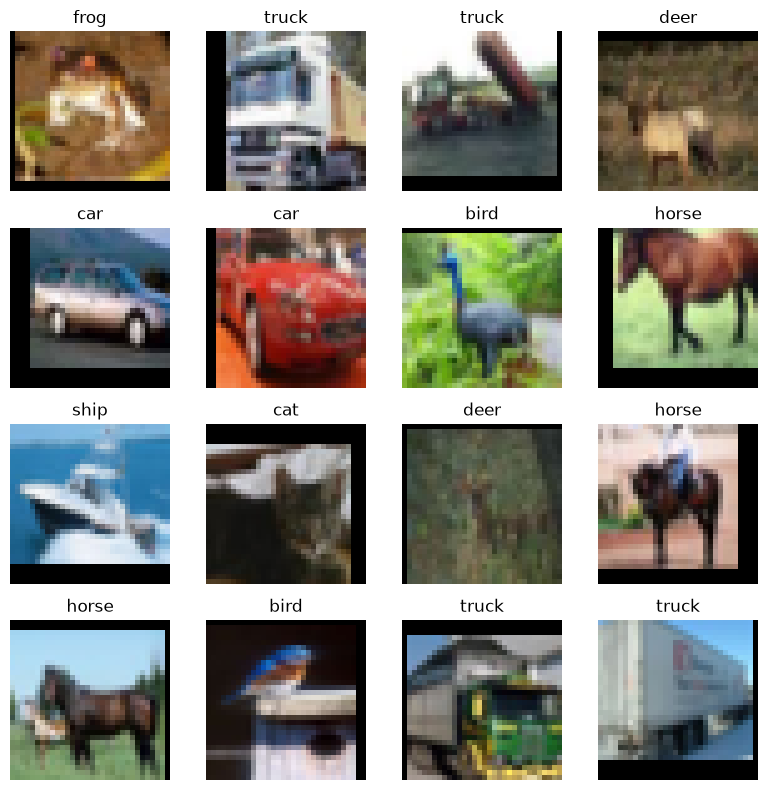

In [6]:
set_seed(CFG['seed'])
RUN_DIR = create_run_directory()
train_data, test_data = load_datasets()
show_samples(train_data, RUN_DIR)
results = []


## 6 训练与真实测试集评估

默认完整训练 10 个 epoch。每轮展示训练损失和测试准确率；正式运行时不要使用 smoke_test 的小样本结果代替全量结果。



vgg_simplified: 9,231,114 parameters, 10 epoch(s)


  Batch 1/391 | loss=2.4393


  Batch 101/391 | loss=1.5108


  Batch 201/391 | loss=1.1445


  Batch 301/391 | loss=1.3841


...

Epoch 9/10 | train loss 0.4168 | test loss 0.5537 | test accuracy 81.58% (10000 samples)
  Batch 1/391 | loss=0.4813


  Batch 101/391 | loss=0.3396


  Batch 201/391 | loss=0.3916


  Batch 301/391 | loss=0.3729


Epoch 10/10 | train loss 0.3919 | test loss 0.5804 | test accuracy 80.36% (10000 samples)


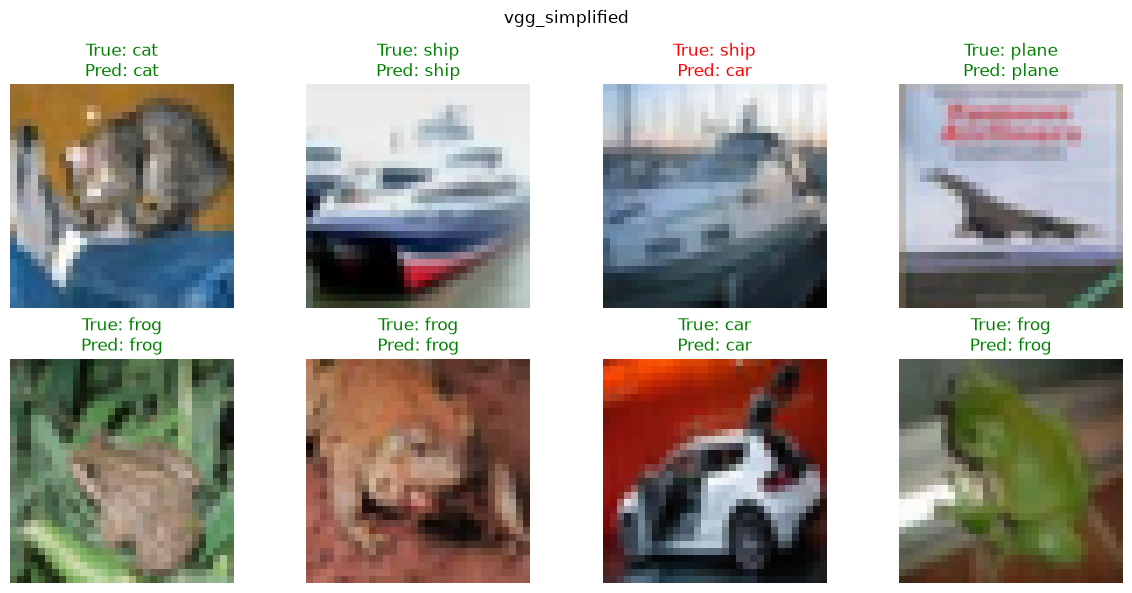

In [7]:
set_seed(CFG['seed'])
model = VGG().to(DEVICE)
result = fit_model(model, 'vgg_simplified', train_data, test_data, RUN_DIR, nn.CrossEntropyLoss())
results = [result]
show_predictions(result, test_data, RUN_DIR)


## 8 汇总结果与导出

生成训练曲线、summary.csv、各模型 history.csv、预测图片与模型权重。ZIP 仅包含本次运行结果。导出后还应从 Colab 下载带单元输出的 ipynb，保留真实执行证据。


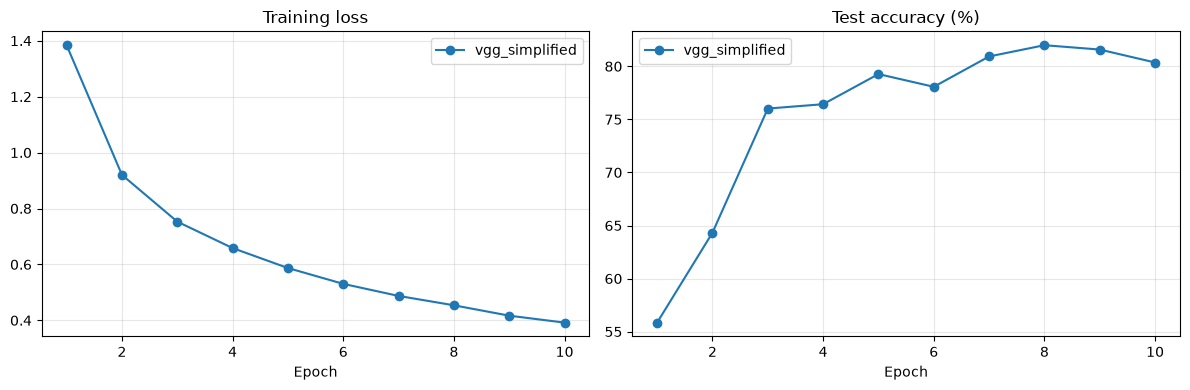


Model | Parameters | Test accuracy (%)
vgg_simplified | 9,231,114 | 80.36


Results ZIP: C:\Users\chuan\OneDrive\Desktop\软件工程实验3_CNN代码\outputs\lab05_vgg_cifar10\20261016_191055_761683.zip
请同时保存带运行输出的 Notebook，作为报告截图的原始依据。


In [8]:
summary = save_comparison(results, RUN_DIR)
archive_path = export_results(RUN_DIR)


## 报告记录提示

记录本次环境、参数、数据规模、训练过程、最终准确率和错误预测。选择环境检查、尺寸检查、训练日志、预测图、结果汇总作为截图。随机种子不保证不同设备和软件版本逐位一致；以本次真实结果为准。
